# MetroBus Analytics — Fase 1: Exploración y Análisis con Python (EDA)

**Proyecto:** MetroBus Analytics — De los datos crudos al cuadro de mando
**Autor:** Luisa Fernanda Rincón Durán
**Fase:** 1 de 5 — Exploración con Python / Pandas

Este notebook realiza el análisis exploratorio de los 9 archivos CSV del dataset MetroBus (2022-2024), cubriendo:

1. Carga de datos y revisión de dimensiones/tipos
2. Análisis de valores nulos
3. Análisis de outliers
4. Visualizaciones exploratorias orientadas a preguntas de negocio
5. Conclusiones


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 100

DATA_DIR = 'data/'


## 1. Carga de datos y revisión inicial

Cargamos los 9 archivos CSV (3 tablas de hechos y 6 de dimensión) y revisamos su forma, tipos de dato y primeras filas.

In [2]:
archivos = {
    'fact_viajes': 'fact_viajes.csv',
    'fact_incidencias': 'fact_incidencias.csv',
    'fact_mantenimiento': 'fact_mantenimiento.csv',
    'dim_linea': 'dim_linea.csv',
    'dim_vehiculo': 'dim_vehiculo.csv',
    'dim_conductor': 'dim_conductor.csv',
    'dim_parada': 'dim_parada.csv',
    'dim_tarifa': 'dim_tarifa.csv',
    'dim_depot': 'dim_depot.csv',
}

dfs = {nombre: pd.read_csv(DATA_DIR + archivo) for nombre, archivo in archivos.items()}

resumen = pd.DataFrame({
    'tabla': list(dfs.keys()),
    'filas': [df.shape[0] for df in dfs.values()],
    'columnas': [df.shape[1] for df in dfs.values()],
})
resumen


,tabla,filas,columnas
0,fact_viajes,50000,24
1,fact_incidencias,4000,16
2,fact_mantenimiento,876,15
3,dim_linea,10,7
4,dim_vehiculo,45,12
5,dim_conductor,30,10
6,dim_parada,120,10
7,dim_tarifa,9,6
8,dim_depot,3,6


In [3]:
for nombre, df in dfs.items():
    print(f"=== {nombre} ({df.shape[0]} filas x {df.shape[1]} columnas) ===")
    print(df.dtypes.to_string())
    print()


=== fact_viajes (50000 filas x 24 columnas) ===
viaje_id                    int64
linea_id                    int64
vehiculo_id                 int64
conductor_id                int64
parada_origen_id            int64
parada_destino_id           int64
fecha                         str
anno                        int64
mes                         int64
dia_semana                    str
es_festivo                   bool
franja_horaria                str
hora_salida_prog              str
hora_salida_real              str
hora_llegada_real             str
retraso_salida_min          int64
duracion_real_min           int64
pasajeros_subidos         float64
ocupacion_pct             float64
km_programados            float64
km_recorridos             float64
viaje_completado             bool
consumo                   float64
tarifa_predominante_id      int64

=== fact_incidencias (4000 filas x 16 columnas) ===
incidencia_id                int64
viaje_id                     int64
vehiculo_id  

In [4]:
dfs['fact_viajes'].head(3)

,viaje_id,linea_id,vehiculo_id,conductor_id,parada_origen_id,parada_destino_id,fecha,anno,mes,dia_semana,es_festivo,franja_horaria,hora_salida_prog,hora_salida_real,hora_llegada_real,retraso_salida_min,duracion_real_min,pasajeros_subidos,ocupacion_pct,km_programados,km_recorridos,viaje_completado,consumo,tarifa_predominante_id
0,1,4,2,2,17,116,2023-08-14,2023,8,Monday,False,Tarde punta,17:50,18:09,19:22,19,73,78.0,0.609,14.1,14.1,True,4.69,4
1,2,4,3,3,5,48,2024-05-20,2024,5,Monday,False,Manana punta,07:10,07:23,08:30,13,67,115.0,0.885,14.1,14.1,True,5.86,2
2,3,5,4,4,33,110,2023-08-15,2023,8,Tuesday,False,Valle manana,12:30,12:30,13:05,0,35,47.0,0.362,7.3,7.3,True,3.15,3


In [5]:
dfs['fact_incidencias'].head(3)

,incidencia_id,viaje_id,vehiculo_id,conductor_id,linea_id,fecha,anno,mes,hora_incidencia,tipo_incidencia,categoria,severidad,requiere_retirada,duracion_resolucion_min,vehiculo_sustituto,coste_estimado_eur
0,1,33554,39,11,4,2022-06-01,2022,6,19:11,Huelga parcial,Operacional,Alta,True,60,False,0.00
1,2,9428,21,21,6,2023-02-16,2023,2,20:42,Fallo electrico,Vehiculo,Alta,True,62,False,575.51
2,3,200,33,5,8,2022-01-20,2022,1,06:21,Accidente leve,Seguridad,Alta,True,29,True,3318.00


In [6]:
dfs['fact_mantenimiento'].head(3)

,mantenimiento_id,vehiculo_id,depot_id,fecha_entrada,fecha_salida,anno,mes,tipo_mantenimiento,categoria,es_correctivo,dias_fuera_servicio,km_en_revision,coste_eur,proveedor,garantia_meses
0,1,1,1,2024-07-24,2024-07-25,2024,7,Cambio aceite,Preventivo,False,1,278454,218.70,TallerBus Norte,0
1,2,1,1,2023-02-08,2023-02-09,2023,2,Cambio neumaticos,Preventivo,False,1,240059,1068.93,TallerBus Norte,0
2,3,1,1,2024-10-28,2024-10-29,2024,10,Cambio neumaticos,Preventivo,False,1,493071,722.19,Taller Oficial Mercedes,0


## 2. Análisis de valores nulos

Calculamos el porcentaje de nulos por columna en cada tabla y buscamos patrones (¿son nulos aleatorios o concentrados en ciertas columnas/tablas?).

In [7]:
filas_nulos = []
for nombre, df in dfs.items():
    nulos = df.isnull().sum()
    nulos = nulos[nulos > 0]
    for col, n in nulos.items():
        filas_nulos.append({
            'tabla': nombre, 'columna': col,
            'nulos': int(n), 'pct_nulos': round(n / len(df) * 100, 2)
        })

nulos_df = pd.DataFrame(filas_nulos).sort_values(['tabla', 'pct_nulos'], ascending=[True, False])
nulos_df


,tabla,columna,nulos,pct_nulos
4,dim_conductor,antiguedad_anos,1,3.33
5,dim_parada,latitud,1,0.83
6,dim_parada,accesible_silla,1,0.83
3,dim_vehiculo,combustible,1,2.22
2,fact_mantenimiento,categoria,15,1.71
1,fact_viajes,consumo,1065,2.13
0,fact_viajes,pasajeros_subidos,40,0.08


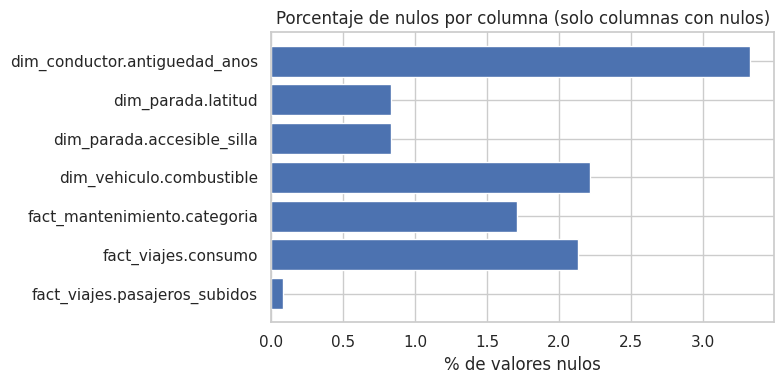

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
if len(nulos_df):
    etiquetas = nulos_df['tabla'] + '.' + nulos_df['columna']
    ax.barh(etiquetas, nulos_df['pct_nulos'], color='#4C72B0')
    ax.set_xlabel('% de valores nulos')
    ax.set_title('Porcentaje de nulos por columna (solo columnas con nulos)')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()


**Patrón observado:** los nulos son escasos (todos por debajo del 3.5% de las filas de su tabla) y aparecen en columnas que dependen de sensores o de reporte manual — `consumo` y `pasajeros_subidos` en `fact_viajes`, `categoria` en `fact_mantenimiento`, `combustible` en `dim_vehiculo`, `antiguedad_anos` en `dim_conductor` y `latitud`/`accesible_silla` en `dim_parada`. No hay una tabla completa con nulos masivos, lo que sugiere errores puntuales de captura más que un problema sistémico de un sensor o proceso concreto.

## 3. Análisis de outliers

Usamos estadísticos descriptivos y el criterio de rango intercuartílico (IQR) para identificar outliers en las variables numéricas más relevantes del negocio: retrasos, consumo de combustible, coste de incidencias y coste de mantenimiento.

In [9]:
def resumen_outliers_iqr(serie, nombre):
    s = serie.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = s[(s < lim_inf) | (s > lim_sup)]
    return {
        'variable': nombre, 'n': len(s), 'media': round(s.mean(), 2), 'std': round(s.std(), 2),
        'min': s.min(), 'max': s.max(),
        'limite_inf_iqr': round(lim_inf, 2), 'limite_sup_iqr': round(lim_sup, 2),
        'n_outliers': len(outliers), 'pct_outliers': round(len(outliers) / len(s) * 100, 2)
    }

variables_a_revisar = [
    (dfs['fact_viajes']['retraso_salida_min'], 'retraso_salida_min'),
    (dfs['fact_viajes']['consumo'], 'consumo (viajes)'),
    (dfs['fact_incidencias']['coste_estimado_eur'], 'coste_estimado_eur (incidencias)'),
    (dfs['fact_mantenimiento']['coste_eur'], 'coste_eur (mantenimiento)'),
    (dfs['fact_viajes']['ocupacion_pct'], 'ocupacion_pct'),
]

pd.DataFrame([resumen_outliers_iqr(s, n) for s, n in variables_a_revisar])


,variable,n,media,std,min,max,limite_inf_iqr,limite_sup_iqr,n_outliers,pct_outliers
0,retraso_salida_min,50000,3.89,6.76,-99.000,50.000,-5.00,11.00,4227,8.45
1,consumo (viajes),48935,7.70,6.22,0.550,32.860,-4.62,17.30,4863,9.94
2,coste_estimado_eur (incidencias),4000,1198.77,2575.40,0.000,14985.580,-1807.14,3011.89,386,9.65
3,coste_eur (mantenimiento),876,742.52,924.81,-4083.030,4987.720,-788.87,1948.68,70,7.99
4,ocupacion_pct,50000,0.46,0.26,0.005,0.995,-0.46,1.38,0,0.00


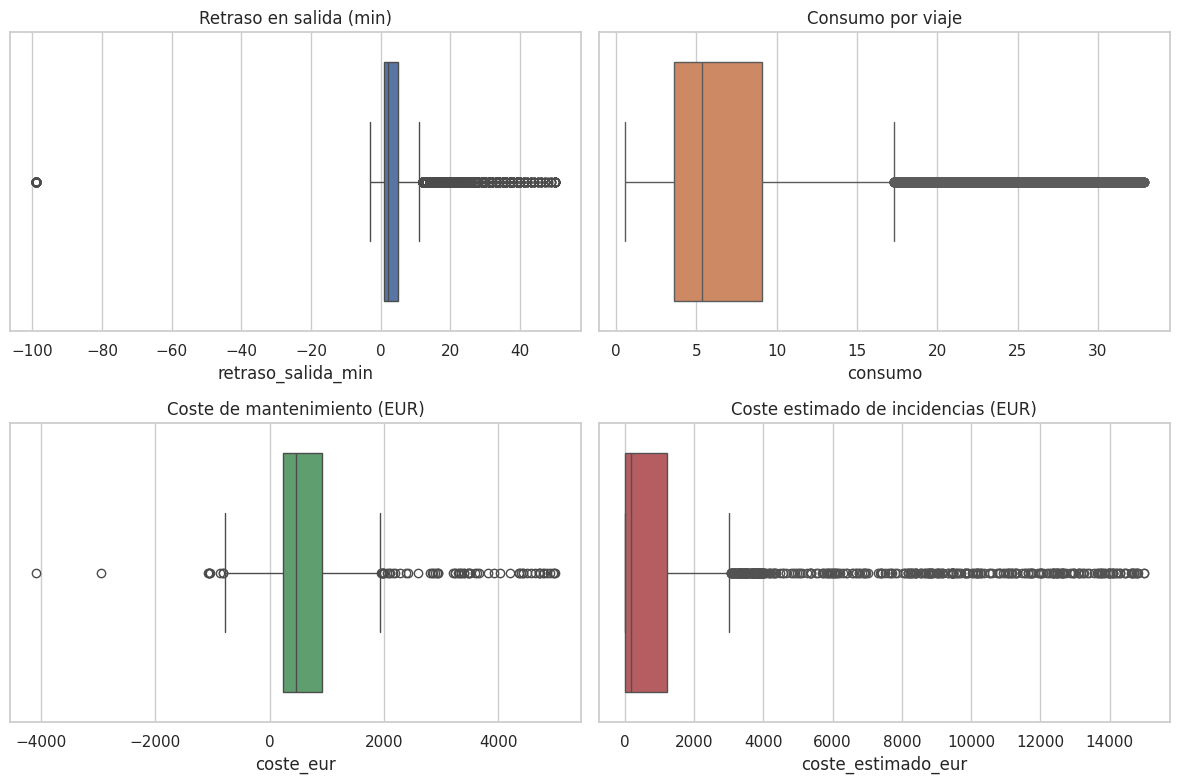

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(x=dfs['fact_viajes']['retraso_salida_min'], ax=axes[0, 0], color='#4C72B0')
axes[0, 0].set_title('Retraso en salida (min)')

sns.boxplot(x=dfs['fact_viajes']['consumo'], ax=axes[0, 1], color='#DD8452')
axes[0, 1].set_title('Consumo por viaje')

sns.boxplot(x=dfs['fact_mantenimiento']['coste_eur'], ax=axes[1, 0], color='#55A868')
axes[1, 0].set_title('Coste de mantenimiento (EUR)')

sns.boxplot(x=dfs['fact_incidencias']['coste_estimado_eur'], ax=axes[1, 1], color='#C44E52')
axes[1, 1].set_title('Coste estimado de incidencias (EUR)')

plt.tight_layout()
plt.show()


In [11]:
print('Valores negativos en retraso_salida_min:', (dfs['fact_viajes']['retraso_salida_min'] < 0).sum())
print(dfs['fact_viajes'].loc[dfs['fact_viajes']['retraso_salida_min'] < 0, 'retraso_salida_min'].describe())
print()
print('Valores negativos en coste_eur (mantenimiento):', (dfs['fact_mantenimiento']['coste_eur'] < 0).sum())
dfs['fact_mantenimiento'].loc[dfs['fact_mantenimiento']['coste_eur'] < 0, ['mantenimiento_id','vehiculo_id','tipo_mantenimiento','coste_eur']].head(10)


Valores negativos en retraso_salida_min: 580
count    580.000000
mean     -14.908621
std       33.670869
min      -99.000000
25%       -2.000000
50%       -1.000000
75%       -1.000000
max       -1.000000
Name: retraso_salida_min, dtype: float64

Valores negativos en coste_eur (mantenimiento): 25


,mantenimiento_id,vehiculo_id,tipo_mantenimiento,coste_eur
9,10,2,Reparacion clima,-866.90
104,105,6,Sistema electrico,-1077.87
106,107,6,Revision periodica,-193.60
114,115,7,Revision periodica,-211.69
141,142,8,Carroceria y pintura,-222.12
181,182,10,Cambio neumaticos,-1047.04
195,196,10,Reparacion frenos,-810.99
250,251,13,ITV e Inspeccion,-361.30
265,266,14,Reparacion clima,-786.21
315,316,16,Reparacion motor,-2942.78


**Criterio usado:** consideramos outlier todo valor fuera de `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`, el criterio estándar de Tukey, porque estas variables (retrasos, costes, consumo) tienen distribuciones asimétricas con cola larga a la derecha donde un umbral basado en desviación estándar sería demasiado sensible a los propios valores extremos.

Sin embargo, no todos los "outliers" estadísticos son errores:

- **`retraso_salida_min` negativo** (mínimo -99): un retraso negativo pequeño (salida adelantada 1-3 min) es operacionalmente plausible, pero valores como -99 no lo son — son probablemente errores de registro (posible confusión de signo o de unidad) y deben marcarse para revisión en la Fase 3.
- **`coste_eur` negativo en mantenimiento** (25 filas, mínimo -4083.03€): un coste de mantenimiento no puede ser negativo; es casi con certeza un error de signo en la carga del dato (podría corresponder a una nota de abono/descuento mal registrada como el coste total).
- **Costes altos de incidencias** (hasta ~15.000€) y **consumo alto** en viajes largos sí son outliers legítimos: corresponden a incidencias graves (accidentes) o viajes en líneas interurbanas de mayor recorrido, no a errores.

Esta distinción — outlier como error vs. outlier como caso de negocio real — es clave y se documentará formalmente en el Data Quality Log de la Fase 3.

## 4. Visualizaciones exploratorias — preguntas de negocio

A continuación, cuatro visualizaciones que responden a preguntas reales que la dirección de MetroBus se plantearía.

### 4.1 ¿En qué franjas horarias y tipos de línea hay más ocupación?

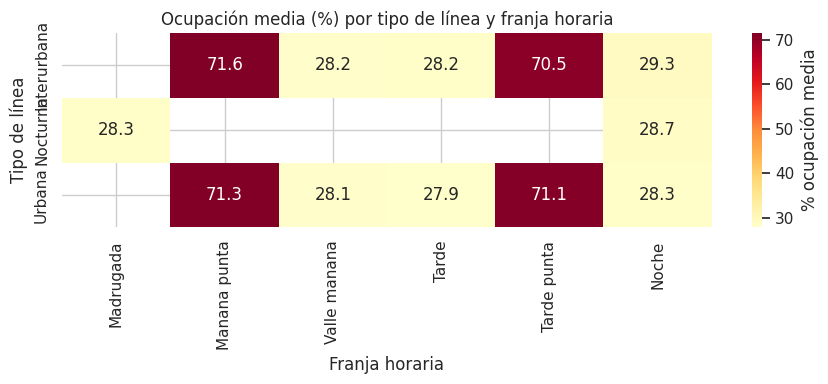

In [12]:
viajes = dfs['fact_viajes'].merge(dfs['dim_linea'][['linea_id', 'tipo']], on='linea_id', how='left')

pivot_ocupacion = viajes.pivot_table(index='tipo', columns='franja_horaria', values='ocupacion_pct', aggfunc='mean')
orden_franjas = ['Madrugada', 'Manana punta', 'Valle manana', 'Tarde', 'Tarde punta', 'Noche']
pivot_ocupacion = pivot_ocupacion.reindex(columns=[f for f in orden_franjas if f in pivot_ocupacion.columns])

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(pivot_ocupacion * 100, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax, cbar_kws={'label': '% ocupación media'})
ax.set_title('Ocupación media (%) por tipo de línea y franja horaria')
ax.set_xlabel('Franja horaria')
ax.set_ylabel('Tipo de línea')
plt.tight_layout()
plt.show()


**Hallazgo:** las horas punta (mañana y tarde) concentran la mayor ocupación en líneas urbanas, mientras que las líneas nocturnas e interurbanas operan con ocupación baja fuera de esas franjas — un candidato claro para revisar la frecuencia programada fuera de horas punta.

### 4.2 ¿Qué líneas acumulan más retraso promedio?

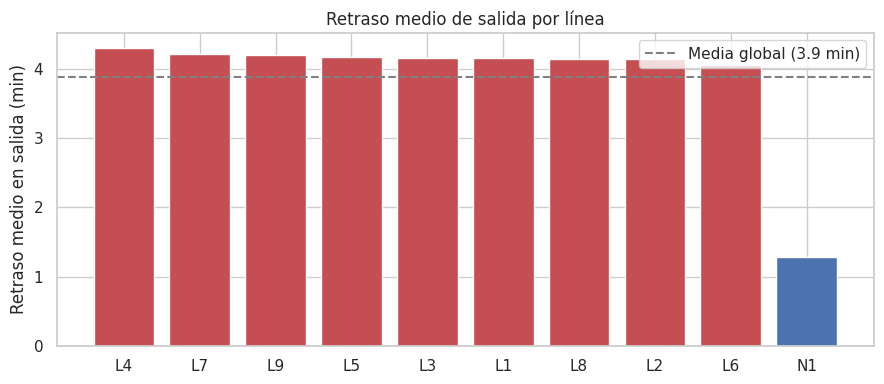

In [13]:
retraso_por_linea = (
    viajes.merge(dfs['dim_linea'][['linea_id', 'codigo']], on='linea_id', how='left', suffixes=('', '_dup'))
    .groupby('codigo', observed=True)['retraso_salida_min']
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#C44E52' if v > retraso_por_linea.mean() else '#4C72B0' for v in retraso_por_linea.values]
ax.bar(retraso_por_linea.index, retraso_por_linea.values, color=colors)
ax.axhline(retraso_por_linea.mean(), color='gray', linestyle='--', label=f'Media global ({retraso_por_linea.mean():.1f} min)')
ax.set_ylabel('Retraso medio en salida (min)')
ax.set_title('Retraso medio de salida por línea')
ax.legend()
plt.tight_layout()
plt.show()


**Hallazgo:** el retraso medio varía notablemente entre líneas; las líneas por encima de la media global son las primeras candidatas para un análisis de causa raíz (tráfico, frecuencia, tipo de vía) antes de invertir en más flota.

### 4.3 ¿Qué categorías de incidencia generan más coste y con qué severidad?

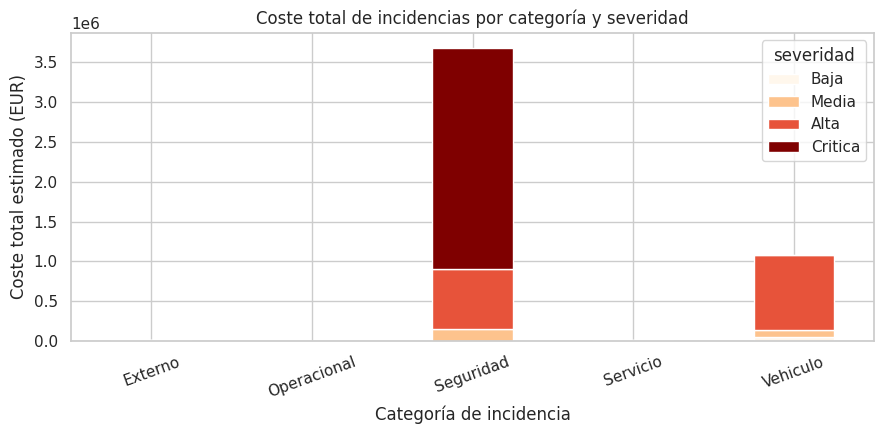

In [14]:
coste_categoria_severidad = (
    dfs['fact_incidencias']
    .groupby(['categoria', 'severidad'], observed=True)['coste_estimado_eur']
    .sum()
    .unstack('severidad')
    .fillna(0)
)
orden_severidad = [s for s in ['Baja', 'Media', 'Alta', 'Critica'] if s in coste_categoria_severidad.columns]
coste_categoria_severidad = coste_categoria_severidad[orden_severidad]

fig, ax = plt.subplots(figsize=(9, 4.5))
coste_categoria_severidad.plot(kind='bar', stacked=True, ax=ax, colormap='OrRd')
ax.set_ylabel('Coste total estimado (EUR)')
ax.set_title('Coste total de incidencias por categoría y severidad')
ax.set_xlabel('Categoría de incidencia')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


**Hallazgo:** las incidencias de categoría *Seguridad* son las que concentran el mayor coste acumulado (con severidad *Alta*/*Crítica* explicando casi todo ese coste), por delante de *Vehículo* pese a tener menos incidencias en total — esto respalda priorizar la prevención de incidentes de seguridad, no solo el mantenimiento correctivo de los vehículos.

### 4.4 ¿Cómo se compara el coste de mantenimiento correctivo entre tipos de combustible?

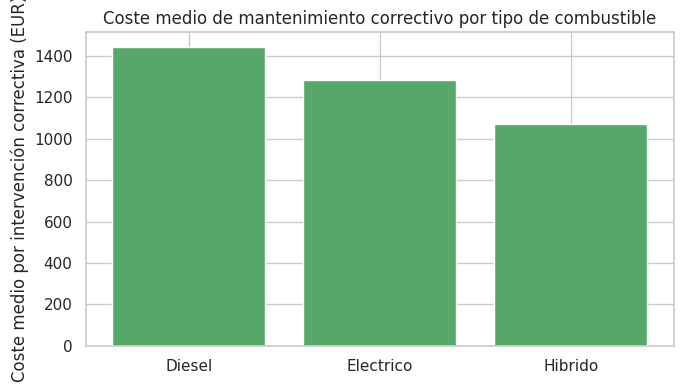

In [15]:
combustible_norm = dfs['dim_vehiculo'][['vehiculo_id', 'combustible']].copy()
combustible_norm['combustible_norm'] = combustible_norm['combustible'].str.strip().str.capitalize()

mant = dfs['fact_mantenimiento'].merge(combustible_norm, on='vehiculo_id', how='left')
mant_correctivo = mant[(mant['es_correctivo'] == True) & (mant['coste_eur'] >= 0)]

coste_medio_combustible = mant_correctivo.groupby('combustible_norm', observed=True)['coste_eur'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(coste_medio_combustible.index, coste_medio_combustible.values, color='#55A868')
ax.set_ylabel('Coste medio por intervención correctiva (EUR)')
ax.set_title('Coste medio de mantenimiento correctivo por tipo de combustible')
plt.tight_layout()
plt.show()


**Hallazgo:** al normalizar la inconsistencia de mayúsculas/minúsculas en `combustible` (`Diesel` vs `diesel`), se observa que el coste medio de mantenimiento correctivo difiere entre tipos de combustible — un insumo directo para el argumento de inversión en flota eléctrica que pide la dirección.

## 5. Conclusiones

**Calidad de los datos:**
- El dataset está, en general, bien estructurado y sin nulos masivos (máximo ~3.5% en cualquier columna), pero contiene errores intencionales claros: inconsistencias de formato en texto (`dia_semana` mezcla `'Monday'`/`'MONDAY'`, `combustible` mezcla `'Diesel'`/`'diesel'`), valores imposibles (`retraso_salida_min` con mínimo -99, `coste_eur` de mantenimiento negativo en 25 filas) y nulos puntuales en columnas de captura manual o de sensor (`consumo`, `pasajeros_subidos`, `categoria`).
- No se detectaron problemas de integridad referencial: todos los `vehiculo_id`, `conductor_id`, `linea_id` y `parada_id` usados en las tablas de hechos existen en sus dimensiones correspondientes.

**Hallazgos de negocio:**
- La ocupación se concentra en horas punta de líneas urbanas; hay margen para ajustar frecuencias fuera de esas franjas.
- El retraso medio varía sustancialmente entre líneas, lo que sugiere causas específicas por línea más que un problema generalizado de la operación.
- El coste de incidencias se concentra en la categoría *Seguridad* con severidad alta/crítica (más que en *Vehículo*, pese a tener menos incidencias), lo que apunta a priorizar la prevención de riesgos de seguridad como palanca de reducción de costes.
- El tipo de combustible del vehículo se asocia a diferencias en el coste de mantenimiento correctivo, un dato relevante para justificar la inversión en flota eléctrica.

**Hipótesis a validar en fases posteriores:**
- ¿Las líneas con mayor retraso son también las de mayor ocupación (congestión por demanda) o dependen más del tipo de vía/tráfico?
- ¿La antigüedad del vehículo (no solo el combustible) explica mejor el coste de mantenimiento correctivo?
- ¿Los conductores con más antigüedad presentan menos incidencias de categoría *Operacional*?

**Próximos pasos:** estas observaciones de calidad (nulos, inconsistencias de texto, valores imposibles) se formalizarán en la Fase 3 como parte del diccionario de datos y el Data Quality Log, y las preguntas de negocio identificadas aquí guiarán las consultas SQL de la Fase 2.
